# U-Net on your new dataset

Select the project `.venv` kernel and run all cells. Images are in `data/936/data`; same-name masks are in `data/936/mask`. Defaults: images 1Ã¢â‚¬â€œ5, up to 120 epochs, RGB input, three-class softmax, 128x128 resolution, 16 base filters. Class IDs are preserved as 0, 1, and 2; semantic names are not assumed.

`LIMIT=5` uses the same images for training and evaluation, so metrics are a sanity check. Set `LIMIT=None` for the full dataset with a separate held-out test split.

The multiclass head uses all decoder features. For this tiny sanity run, dropout is disabled, the initial learning rate is 0.001, and training runs for 120 epochs. Outputs are model predictions, not altered ground-truth masks.

Run `dataPrepare.ipynb` first to inspect pairs and save the preparation manifest. This notebook imports shared helpers from `data.py` and orchestration from `main.py`; `main.py` builds the U-Net from `model.py`. If preparation was skipped, `prepare_run` validates the same dataset automatically.


In [7]:
import json, os, sys
from pathlib import Path
from types import SimpleNamespace
from datetime import datetime
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import numpy as np
from PIL import Image
import tensorflow as tf
import matplotlib.pyplot as plt
from data import make_dataset, plot_predictions
from main import prepare_run, train_model, evaluate_model

# Set LIMIT=None for all 936 pairs with a held-out test split.
DATASET = Path('data/936')
LIMIT = 5
EPOCHS = 120
IMAGE_SIZE = 128
BATCH_SIZE = 4
BASE_FILTERS = 16
LEARNING_RATE = 1e-3
DROPOUT_RATE = 0.0 if LIMIT is not None else 0.5
OUTPUT = Path('runs') / ('notebook_five_images_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
args = SimpleNamespace(dataset=DATASET, limit=LIMIT, epochs=EPOCHS,
    size=IMAGE_SIZE, batch_size=BATCH_SIZE, base_filters=BASE_FILTERS, learning_rate=LEARNING_RATE, dropout_rate=DROPOUT_RATE, output=OUTPUT)
if IMAGE_SIZE < 16 or IMAGE_SIZE % 16:
    raise ValueError('IMAGE_SIZE must be a positive multiple of 16')
if min(EPOCHS, BATCH_SIZE, BASE_FILTERS) < 1 or (LIMIT is not None and LIMIT < 1):
    raise ValueError('All parameters must be positive')
print('Python:', sys.executable)
print('TensorFlow:', tf.__version__)
print('Dataset:', DATASET.resolve())


Python: e:\AamadNaseem\MSAIEngineering\2.SemesterFall2026\DeepLearning\unet\.venv\Scripts\python.exe
TensorFlow: 2.21.0
Dataset: E:\AamadNaseem\MSAIEngineering\2.SemesterFall2026\DeepLearning\unet\data\936


## Inspect and validate image/mask pairs


In [8]:
images, masks, manifest, settings = prepare_run(args)
print('Selected pairs:', manifest)
print('Used dataPrepare.ipynb manifest:', settings['prepared_manifest_used'])


Selected pairs: {'train': ['1', '2', '3', '4', '5'], 'validation': ['1', '2', '3', '4', '5'], 'test': ['1', '2', '3', '4', '5']}
Used dataPrepare.ipynb manifest: False


## Load and preprocess images and indexed masks


In [9]:
datasets = {name: make_dataset(images, masks, ids, size=args.size,
    batch_size=args.batch_size, training=name == 'train') for name, ids in manifest.items()}
train, val, test = datasets['train'], datasets['validation'], datasets['test']
print('Dataset batches:', {name: len(ds) for name, ds in datasets.items()})


Dataset batches: {'train': 2, 'validation': 2, 'test': 2}


## Train U-Net


In [10]:
model, history = train_model(args, train, val)


Dataset split: {'train_batches': 2, 'validation_batches': 2}
Parameters: 1941139 Hardware: ["PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')"]
Epoch 1/120
2/2 - 4s - 2s/step - accuracy: 0.2585 - loss: 1.5712 - val_accuracy: 0.5243 - val_loss: 1.0382 - learning_rate: 0.0010
Epoch 2/120
2/2 - 0s - 75ms/step - accuracy: 0.5131 - loss: 1.0460 - val_accuracy: 0.5186 - val_loss: 1.0523 - learning_rate: 0.0010
Epoch 3/120
2/2 - 0s - 141ms/step - accuracy: 0.5187 - loss: 1.0540 - val_accuracy: 0.5399 - val_loss: 1.0367 - learning_rate: 0.0010
Epoch 4/120
2/2 - 0s - 143ms/step - accuracy: 0.5392 - loss: 1.0347 - val_accuracy: 0.5450 - val_loss: 1.0066 - learning_rate: 0.0010
Epoch 5/120
2/2 - 0s - 139ms/step - accuracy: 0.5461 - loss: 1.0026 - val_accuracy: 0.5439 - val_loss: 0.9941 - learning_rate: 0.0010
Epoch 6/120
2/2 - 0s - 74ms/step - accuracy: 0.5427 - loss: 0.9866 - val_accuracy: 0.3895 - val_loss: 1.1291 - learning_rate: 0.0010
Epoch 7/120
2/2 - 0s - 74ms/step - accura

## Evaluate and save model predictions


In [11]:
model, metrics, pred_dir = evaluate_model(args, test, manifest, settings)


2/2 - 1s - 292ms/step - accuracy: 0.8599 - loss: 0.3828
Predicted pixel counts by class ID: [47461, 14537, 19922]
Evaluation metrics: {"accuracy": 0.8599487543106079, "loss": 0.38284072279930115, "predicted_pixels_by_class_id": [47461, 14537, 19922], "evaluation_scope": "same training samples - sanity check only", "dice_by_class_id": [0.8954282711508145, 0.8175512381908917, 0.8094082412475473], "macro_dice": 0.8407959168630845, "confusion_matrix": [[41748, 1225, 2813], [2866, 13024, 1434], [2847, 288, 15675]]}
Artifacts: E:\AamadNaseem\MSAIEngineering\2.SemesterFall2026\DeepLearning\unet\runs\notebook_five_images_20261010_220556


## Compare images, ground truth, and predictions
This five-image run is intentionally trained longer to check whether the model can fit the samples; same-sample metrics do not measure unseen-image performance.


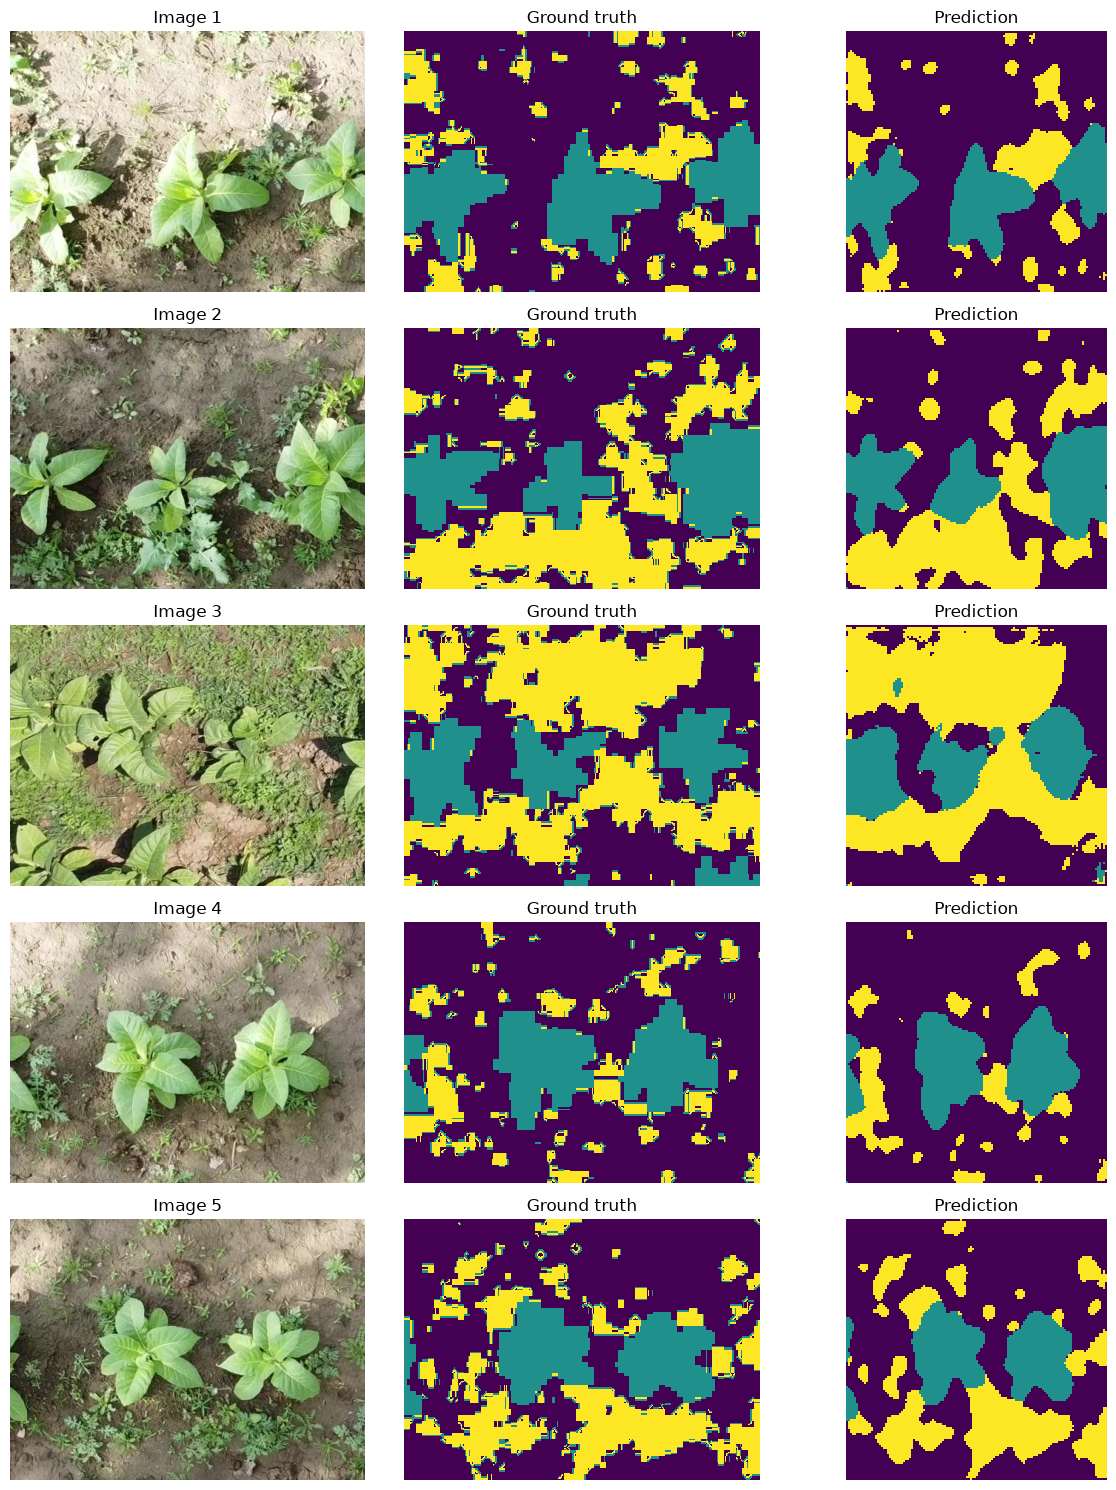

Artifacts: E:\AamadNaseem\MSAIEngineering\2.SemesterFall2026\DeepLearning\unet\runs\notebook_five_images_20261010_220556


In [12]:
fig = plot_predictions(images, masks, manifest['test'], pred_dir, args.output)
plt.show()
print('Artifacts:', args.output.resolve())
